In [ ]:
#CONNECT GPU

MODULE 1

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install datasets transformers torch accelerate -q

In [ ]:
import os
import random
import numpy as np
import torch
from datasets import load_dataset, DatasetDict
from transformers import RobertaTokenizer
import json
from collections import defaultdict

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
print("✓ Libraries imported and seed set")

✓ Libraries imported and seed set


In [ ]:
# Directory in Google Drive to save datasets
SAVE_DIR = '/content/drive/MyDrive/FYP_GradientFree_LoRA/'
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(os.path.join(SAVE_DIR, 'datasets'), exist_ok=True)

print(f"✓ Datasets will be saved to: {SAVE_DIR}")

✓ Datasets will be saved to: /content/drive/MyDrive/FYP_GradientFree_LoRA/


In [ ]:
# Patterns and verbalizers for each dataset
DATASET_CONFIG = {
    'sst2': {
        'dataset_name': 'sst2',
        'dataset_config': None,
        'text_column': 'sentence',
        'label_column': 'label',
        'pattern': lambda text: f"{text} It was <mask>.",
        'verbalizers': {0: "bad", 1: "great"},
        'num_classes': 2,
        'use_validation_as_test': True  # SST-2 test set has no labels
    },
    'yelp_polarity': {
        'dataset_name': 'yelp_polarity',
        'dataset_config': None,
        'text_column': 'text',
        'label_column': 'label',
        'pattern': lambda text: f"{text} It was <mask>.",
        'verbalizers': {0: "bad", 1: "great"},
        'num_classes': 2,
        'use_validation_as_test': False
    },
    'ag_news': {
        'dataset_name': 'ag_news',
        'dataset_config': None,
        'text_column': 'text',
        'label_column': 'label',
        'pattern': lambda text: f"<mask> News {text}.",
        'verbalizers': {0: "World", 1: "Sports", 2: "Business", 3: "Tech"},
        'num_classes': 4,
        'use_validation_as_test': False
    },
    'dbpedia_14': {
        'dataset_name': 'dbpedia_14',
        'dataset_config': None,
        'text_column': 'content',
        'label_column': 'label',
        'pattern': lambda text: f"Category: <mask> {text}",
        'verbalizers': {
            0: "Company", 1: "Education", 2: "Artist", 3: "Athlete",
            4: "Office", 5: "Transportation", 6: "Building", 7: "Natural",
            8: "Village", 9: "Animal", 10: "Plant", 11: "Album",
            12: "Film", 13: "Written"
        },
        'num_classes': 14,
        'use_validation_as_test': False
    }
}

print("✓ Dataset configurations defined")
print(f"Datasets to process: {list(DATASET_CONFIG.keys())}")

✓ Dataset configurations defined
Datasets to process: ['sst2', 'yelp_polarity', 'ag_news', 'dbpedia_14']


In [ ]:
# Initializing RoBERTa tokenizer
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
print("✓ RoBERTa tokenizer loaded")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✓ RoBERTa tokenizer loaded


In [ ]:
def create_few_shot_split(dataset, n_samples_per_class, num_classes, label_column, seed=42):

    random.seed(seed)
    np.random.seed(seed)

    # Group samples by class
    class_samples = defaultdict(list)
    for idx, example in enumerate(dataset):
        label = example[label_column]
        class_samples[label].append(idx)

    # Sample n instances per class for train and dev
    train_indices = []
    dev_indices = []

    for label in range(num_classes):
        if label not in class_samples:
            print(f"Warning: No samples found for class {label}")
            continue

        samples = class_samples[label]
        random.shuffle(samples)


        if len(samples) < 2 * n_samples_per_class:
            print(f"Warning: Class {label} has only {len(samples)} samples, need {2*n_samples_per_class}")
            n = min(n_samples_per_class, len(samples) // 2)
        else:
            n = n_samples_per_class

        train_indices.extend(samples[:n])
        dev_indices.extend(samples[n:2*n])

    train_split = dataset.select(train_indices)
    dev_split = dataset.select(dev_indices)

    return train_split, dev_split

print("✓ Few-shot split function defined")

✓ Few-shot split function defined


In [ ]:
def apply_pattern_and_verbalizer(example, config):
    text = example[config['text_column']]
    label = example[config['label_column']]

    max_text_length = 400
    if len(text) > max_text_length:
        text = text[:max_text_length]

    # Apply pattern
    mlm_text = config['pattern'](text)

    # Getting verbalizer for the label
    verbalizer = config['verbalizers'][label]

    return {
        'mlm_text': mlm_text,
        'text': text,
        'label': label,
        'verbalizer': verbalizer
    }

print("✓ Pattern application function defined")

✓ Pattern application function defined


In [ ]:
def process_dataset(dataset_key, n_shot=16, save=True):
    """
    Process a single dataset: load, create few-shot splits, apply patterns
    """
    print(f"\n{'='*60}")
    print(f"Processing {dataset_key} with {n_shot}-shot setting")
    print(f"{'='*60}")

    config = DATASET_CONFIG[dataset_key]

    # Loading dataset
    print("Loading dataset")
    if config['dataset_config']:
        dataset = load_dataset(config['dataset_name'], config['dataset_config'])
    else:
        dataset = load_dataset(config['dataset_name'])


    if config.get('use_validation_as_test', False):
        print("Using validation set as test set (original test set has no labels)")
        train_full = dataset['train']
        test_full = dataset['validation']
    else:
        train_full = dataset['train']
        test_full = dataset['test']


    valid_labels = set(config['verbalizers'].keys())
    print(f"Valid labels: {valid_labels}")

    train_full = train_full.filter(lambda x: x[config['label_column']] in valid_labels)
    test_full = test_full.filter(lambda x: x[config['label_column']] in valid_labels)

    print(f"Original train size (after filtering): {len(train_full)}")
    print(f"Original test size (after filtering): {len(test_full)}")

    # Creating few-shot splits
    print(f"\nCreating {n_shot}-shot splits...")
    train_split, dev_split = create_few_shot_split(
        train_full,
        n_samples_per_class=n_shot,
        num_classes=config['num_classes'],
        label_column=config['label_column'],
        seed=42
    )

    print(f"Few-shot train size: {len(train_split)}")
    print(f"Few-shot dev size: {len(dev_split)}")

    # Apply patterns and verbalizers
    print("\nApplying patterns and verbalizers...")
    train_processed = train_split.map(
        lambda x: apply_pattern_and_verbalizer(x, config),
        batched=False
    )
    dev_processed = dev_split.map(
        lambda x: apply_pattern_and_verbalizer(x, config),
        batched=False
    )
    test_processed = test_full.map(
        lambda x: apply_pattern_and_verbalizer(x, config),
        batched=False
    )

    # Create DatasetDict
    processed_dataset = DatasetDict({
        'train': train_processed,
        'validation': dev_processed,
        'test': test_processed
    })


    print("\n--- Sample from training set ---")
    print(f"Original text: {train_processed[0]['text'][:100]}...")
    print(f"MLM text: {train_processed[0]['mlm_text'][:150]}...")
    print(f"Label: {train_processed[0]['label']}")
    print(f"Verbalizer: {train_processed[0]['verbalizer']}")

    # Save to Google Drive
    if save:
        save_path = os.path.join(SAVE_DIR, 'datasets', f'{dataset_key}_{n_shot}shot')
        print(f"\nSaving to: {save_path}")
        processed_dataset.save_to_disk(save_path)


        config_save = {
            'pattern': str(config['pattern']('TEXT_PLACEHOLDER')),
            'verbalizers': config['verbalizers'],
            'n_shot': n_shot,
            'num_classes': config['num_classes']
        }
        with open(os.path.join(save_path, 'config.json'), 'w') as f:
            json.dump(config_save, f, indent=2)

    print(f"\n✓ {dataset_key} processing complete!")

    return processed_dataset

print("✓ Main processing function defined")

✓ Main processing function defined


In [ ]:
# Set the number of samples per class for few-shot learning
n_shot = 16

print(f"✓ Using {n_shot}-shot setting")

✓ Using 16-shot setting


In [ ]:
# Process SST-2 (Sentiment Analysis)
print("\n" + "="*60)
print("PROCESSING SST-2")
print("="*60)

sst2_dataset = process_dataset('sst2', n_shot=n_shot)


PROCESSING SST-2

Processing sst2 with 16-shot setting
Loading dataset


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.11M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/72.8k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/148k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

... (10 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/872 [00:00<?, ? examples/s]


✓ sst2 processing complete!


In [ ]:
# Process Yelp Polarity (Sentiment Analysis)
print("\n" + "="*60)
print("PROCESSING YELP POLARITY")
print("="*60)

yelp_dataset = process_dataset('yelp_polarity', n_shot=n_shot)


PROCESSING YELP POLARITY

Processing yelp_polarity with 16-shot setting
Loading dataset


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/256M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/560000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/38000 [00:00<?, ? examples/s]

... (8 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/38000 [00:00<?, ? examples/s]


✓ yelp_polarity processing complete!


In [ ]:
# Process AG News (Topic Classification)
print("\n" + "="*60)
print("PROCESSING AG NEWS")
print("="*60)

agnews_dataset = process_dataset('ag_news', n_shot=n_shot)


PROCESSING AG NEWS

Processing ag_news with 16-shot setting
Loading dataset


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

... (8 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/64 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/64 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7600 [00:00<?, ? examples/s]


✓ ag_news processing complete!


In [ ]:
# Process DBPedia (Topic Classification)
print("\n" + "="*60)
print("PROCESSING DBPEDIA")
print("="*60)

dbpedia_dataset = process_dataset('dbpedia_14', n_shot=n_shot)


PROCESSING DBPEDIA

Processing dbpedia_14 with 16-shot setting
Loading dataset


README.md: 0.00B [00:00, ?B/s]

dbpedia_14/train-00000-of-00001.parquet:   0%|          | 0.00/106M [00:00<?, ?B/s]

dbpedia_14/test-00000-of-00001.parquet:   0%|          | 0.00/13.3M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/560000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/70000 [00:00<?, ? examples/s]

... (8 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/224 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/224 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/70000 [00:00<?, ? examples/s]


✓ dbpedia_14 processing complete!


In [ ]:
# Print summary of all processed datasets
print("\n" + "="*60)
print("PROCESSING COMPLETE - SUMMARY")
print("="*60)

processed_datasets = {
    'sst2': sst2_dataset,
    'yelp_polarity': yelp_dataset,
    'ag_news': agnews_dataset,
    'dbpedia_14': dbpedia_dataset
}

for name, ds in processed_datasets.items():
    print(f"\n{name.upper()}:")
    print(f"  Train: {len(ds['train'])} samples")
    print(f"  Validation: {len(ds['validation'])} samples")
    print(f"  Test: {len(ds['test'])} samples")

print(f"\n✓ All datasets saved to: {SAVE_DIR}datasets/")
print("\n--- How to load datasets later ---")
print("from datasets import load_from_disk")
print("dataset = load_from_disk('/content/drive/MyDrive/FYP_GradientFree_LoRA/datasets/sst2_16shot')")


PROCESSING COMPLETE - SUMMARY

SST2:
  Train: 32 samples
  Validation: 32 samples
  Test: 872 samples

YELP_POLARITY:
  Train: 32 samples
  Validation: 32 samples
  Test: 38000 samples

AG_NEWS:
  Train: 64 samples
  Validation: 64 samples
  Test: 7600 samples

DBPEDIA_14:
  Train: 224 samples
  Validation: 224 samples
  Test: 70000 samples

✓ All datasets saved to: /content/drive/MyDrive/FYP_GradientFree_LoRA/datasets/

--- How to load datasets later ---
from datasets import load_from_disk
dataset = load_from_disk('/content/drive/MyDrive/FYP_GradientFree_LoRA/datasets/sst2_16shot')


In [ ]:
import pandas as pd
from IPython.display import display


def display_dataset_as_table(dataset_name, dataset, split='train', max_rows=None):
    print(f"\n{'='*100}")
    print(f"{dataset_name.upper()} - {split.upper()} SPLIT")
    print(f"{'='*100}\n")


    df = dataset[split].to_pandas()


    df['text_preview'] = df['text'].str[:100] + '...'
    df['mlm_text_preview'] = df['mlm_text'].str[:150] + '...'


    display_cols = ['label', 'verbalizer', 'text_preview', 'mlm_text_preview']
    df_display = df[display_cols]


    pd.set_option('display.max_rows', max_rows)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', None)
    pd.set_option('display.max_colwidth', None)

    print(f"Total records: {len(df)}\n")
    display(df_display)

    return df

# Display all datasets

# SST-2
sst2_train_df = display_dataset_as_table('sst2', sst2_dataset, 'train', max_rows=None)
sst2_val_df = display_dataset_as_table('sst2', sst2_dataset, 'validation', max_rows=None)
sst2_test_df = display_dataset_as_table('sst2', sst2_dataset, 'test', max_rows=50)  # Limit test to 50 rows

# Yelp Polarity
yelp_train_df = display_dataset_as_table('yelp_polarity', yelp_dataset, 'train', max_rows=None)
yelp_val_df = display_dataset_as_table('yelp_polarity', yelp_dataset, 'validation', max_rows=None)
yelp_test_df = display_dataset_as_table('yelp_polarity', yelp_dataset, 'test', max_rows=50)

# AG News
agnews_train_df = display_dataset_as_table('ag_news', agnews_dataset, 'train', max_rows=None)
agnews_val_df = display_dataset_as_table('ag_news', agnews_dataset, 'validation', max_rows=None)
agnews_test_df = display_dataset_as_table('ag_news', agnews_dataset, 'test', max_rows=50)

# DBPedia
dbpedia_train_df = display_dataset_as_table('dbpedia_14', dbpedia_dataset, 'train', max_rows=None)
dbpedia_val_df = display_dataset_as_table('dbpedia_14', dbpedia_dataset, 'validation', max_rows=None)
dbpedia_test_df = display_dataset_as_table('dbpedia_14', dbpedia_dataset, 'test', max_rows=50)

print("\n" + "="*100)
print("✓ All datasets displayed!")
print("="*100)


SST2 - TRAIN SPLIT

Total records: 32



,label,verbalizer,text_preview,mlm_text_preview
0,0,bad,exactly how genteel and unsurprising the execution turns out to be ...,exactly how genteel and unsurprising the execution turns out to be It was <mask>....
1,0,bad,an all-time low for kevin costner ...,an all-time low for kevin costner It was <mask>....
2,0,bad,several cliched movie structures : ...,several cliched movie structures : It was <mask>....
3,0,bad,america 's knee-jerk moral sanctimony ...,america 's knee-jerk moral sanctimony It was <mask>....
4,0,bad,a dumb comedy ...,a dumb comedy It was <mask>....
5,0,bad,the plan to make enough into ` an inspiring tale of survival wrapped in the heart-pounding suspense ...,the plan to make enough into ` an inspiring tale of survival wrapped in the heart-pounding suspense of a stylish psychological thriller ' has flopped ...
6,0,bad,"proficient , dull ...","proficient , dull It was <mask>...."
7,0,bad,chitchat that only self-aware neurotics engage in ...,chitchat that only self-aware neurotics engage in It was <mask>....
8,0,bad,tries to cram too many ingredients into one small pot . ...,tries to cram too many ingredients into one small pot . It was <mask>....
9,0,bad,paper-thin characterizations ...,paper-thin characterizations It was <mask>....



SST2 - VALIDATION SPLIT

Total records: 32



,label,verbalizer,text_preview,mlm_text_preview
0,0,bad,bad imitation ...,bad imitation It was <mask>....
1,0,bad,"listless , witless , ...","listless , witless , It was <mask>...."
2,0,bad,gussied up with so many distracting special effects and visual party tricks that it 's not clear whe...,gussied up with so many distracting special effects and visual party tricks that it 's not clear whether we 're supposed to shriek It was <mask>....
3,0,bad,ca n't disguise the fact that it 's inauthentic at its core and that its story just is n't worth tel...,ca n't disguise the fact that it 's inauthentic at its core and that its story just is n't worth telling . It was <mask>....
4,0,bad,put through torture ...,put through torture It was <mask>....
5,0,bad,uncomfortably strained ...,uncomfortably strained It was <mask>....
6,0,bad,is that they 're stuck with a script that prevents them from firing on all cylinders . ...,is that they 're stuck with a script that prevents them from firing on all cylinders . It was <mask>....
7,0,bad,wobbly ...,wobbly It was <mask>....
8,0,bad,sure to ultimately disappoint the action fans who will be moved to the edge of their seats by the dy...,sure to ultimately disappoint the action fans who will be moved to the edge of their seats by the dynamic first act It was <mask>....
9,0,bad,freewheeling trash-cinema roots ...,freewheeling trash-cinema roots It was <mask>....



SST2 - TEST SPLIT

Total records: 872



,label,verbalizer,text_preview,mlm_text_preview
0,1,great,it 's a charming and often affecting journey . ...,it 's a charming and often affecting journey . It was <mask>....
1,0,bad,unflinchingly bleak and desperate ...,unflinchingly bleak and desperate It was <mask>....
2,1,great,allows us to hope that nolan is poised to embark a major career as a commercial yet inventive filmma...,allows us to hope that nolan is poised to embark a major career as a commercial yet inventive filmmaker . It was <mask>....
3,1,great,"the acting , costumes , music , cinematography and sound are all astounding given the production 's ...","the acting , costumes , music , cinematography and sound are all astounding given the production 's austere locales . It was <mask>...."
4,0,bad,"it 's slow -- very , very slow . ...","it 's slow -- very , very slow . It was <mask>...."
...,...,...,...,...
867,0,bad,has all the depth of a wading pool . ...,has all the depth of a wading pool . It was <mask>....
868,1,great,a movie with a real anarchic flair . ...,a movie with a real anarchic flair . It was <mask>....
869,0,bad,a subject like this should inspire reaction in its audience ; the pianist does not . ...,a subject like this should inspire reaction in its audience ; the pianist does not . It was <mask>....
870,0,bad,... is an arthritic attempt at directing by callie khouri . ...,... is an arthritic attempt at directing by callie khouri . It was <mask>....


... (15 outputs left out)

,label,verbalizer,text_preview,mlm_text_preview
0,0,Company,International Tea Co. Stores was a leading chain of grocers based in London. It was a constituent o...,Category: <mask> International Tea Co. Stores was a leading chain of grocers based in London. It was a constituent of the FT 30 index of leading comp...
1,0,Company,First Transit is a United States based subsidiary of FirstGroup. It provides contract public transi...,Category: <mask> First Transit is a United States based subsidiary of FirstGroup. It provides contract public transit and paratransit services transi...
2,0,Company,Shepherd and Wedderburn LLP is a leading commercial law firm headquartered in Edinburgh and with of...,Category: <mask> Shepherd and Wedderburn LLP is a leading commercial law firm headquartered in Edinburgh and with offices in Glasgow Aberdeen and Lon...
3,0,Company,Hulman & Company is a private family-owned company founded in 1850 by Francis Hulman as a wholesale...,Category: <mask> Hulman & Company is a private family-owned company founded in 1850 by Francis Hulman as a wholesale grocery tobacco and liquor store...
4,0,Company,Brashs was one of Australia's biggest music retail chains specializing in the retail of various vin...,Category: <mask> Brashs was one of Australia's biggest music retail chains specializing in the retail of various vinyl records and CDs blank audio ca...
5,0,Company,Science Applications International Corporation (SAIC) is a US company headquartered in McLean Virgi...,Category: <mask> Science Applications International Corporation (SAIC) is a US company headquartered in McLean Virginia that provides government serv...
6,0,Company,The Open Geospatial Consortium (OGC) an international voluntary consensus standards organization or...,Category: <mask> The Open Geospatial Consortium (OGC) an international voluntary consensus standards organization originated in 1994. In the OGC more...
7,0,Company,AET Tanker Holdings Sdn Bhd formerly American Eagle Tankers is a Malaysian-owned global shipping co...,Category: <mask> AET Tanker Holdings Sdn Bhd formerly American Eagle Tankers is a Malaysian-owned global shipping company specialising in the ocean t...
8,0,Company,InterCity Group (NZ) Ltd is a passenger transport and tourism company and operates New Zealand's la...,Category: <mask> InterCity Group (NZ) Ltd is a passenger transport and tourism company and operates New Zealand's largest coach network and ferries a...
9,0,Company,TechnoMarine was founded in 1997 by French entrepreneur Franck Dubarry in Geneva with the launch of...,Category: <mask> TechnoMarine was founded in 1997 by French entrepreneur Franck Dubarry in Geneva with the launch of the Raft a chronograph on a tran...



DBPEDIA_14 - TEST SPLIT

Total records: 70000



,label,verbalizer,text_preview,mlm_text_preview
0,0,Company,TY KU /taɪkuː/ is an American alcoholic beverage company that specializes in sake and other spirits...,Category: <mask> TY KU /taɪkuː/ is an American alcoholic beverage company that specializes in sake and other spirits. The privately-held company was ...
1,0,Company,OddLot Entertainment founded in 2001 by longtime producers Gigi Pritzker and Deborah Del Prete (The...,Category: <mask> OddLot Entertainment founded in 2001 by longtime producers Gigi Pritzker and Deborah Del Prete (The Wedding Planner) is a film produ...
2,0,Company,Henkel AG & Company KGaA operates worldwide with leading brands and technologies in three business ...,Category: <mask> Henkel AG & Company KGaA operates worldwide with leading brands and technologies in three business areas: Laundry & Home Care Beauty...
3,0,Company,The GOAT Store (Games Of All Type Store) LLC is one of the largest retro gaming online stores and a...,Category: <mask> The GOAT Store (Games Of All Type Store) LLC is one of the largest retro gaming online stores and an Independent Video Game Publishi...
4,0,Company,RagWing Aircraft Designs (also called the RagWing Aeroplane Company and RagWing Aviation) was an Am...,Category: <mask> RagWing Aircraft Designs (also called the RagWing Aeroplane Company and RagWing Aviation) was an American aircraft design and manufa...
...,...,...,...,...
69995,13,Written,Energy Victory: Winning the War on Terror by Breaking Free of Oil is a 2007 book by Robert Zubrin. ...,Category: <mask> Energy Victory: Winning the War on Terror by Breaking Free of Oil is a 2007 book by Robert Zubrin. Zubrin's central argument is that...
69996,13,Written,Bestiario is a book of 8 short stories written by Julio Cortázar....,Category: <mask> Bestiario is a book of 8 short stories written by Julio Cortázar....
69997,13,Written,Wuthering Heights is a novel by Emily Brontë written between October 1845 and June 1846 and publish...,Category: <mask> Wuthering Heights is a novel by Emily Brontë written between October 1845 and June 1846 and published in 1847 under the pseudonym El...
69998,13,Written,L'Indépendant is a newspaper published in Luxembourg from 1945....,Category: <mask> L'Indépendant is a newspaper published in Luxembourg from 1945....



✓ All datasets displayed!


In [ ]:
def tokenize_and_prepare_for_mlm(examples, tokenizer, config, max_length=256):

    tokenized = tokenizer(
        examples['mlm_text'],
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors=None
    )

    # Finding mask token position and create verbalizer token ids
    mask_token_id = tokenizer.mask_token_id
    verbalizer_ids = []
    mask_positions = []

    for i, input_ids in enumerate(tokenized['input_ids']):

        try:
            mask_pos = input_ids.index(mask_token_id)
            mask_positions.append(mask_pos)
        except ValueError:

            mask_positions.append(-1)


        label = examples['label'][i]
        verbalizer_text = config['verbalizers'][label]


        verbalizer_tokens = tokenizer(verbalizer_text, add_special_tokens=False)['input_ids']


        if len(verbalizer_tokens) > 0:
            verbalizer_ids.append(verbalizer_tokens[0])
        else:
            verbalizer_ids.append(-100)


    tokenized['mask_position'] = mask_positions
    tokenized['verbalizer_id'] = verbalizer_ids
    tokenized['labels'] = examples['label']

    return tokenized


print("✓ Tokenization function defined")

✓ Tokenization function defined


In [ ]:
print("="*70)
print("TOKENIZING DATASETS")
print("="*70)


MAX_LENGTH = 256

# Store tokenized datasets
tokenized_datasets = {}

datasets_to_tokenize = {
    'sst2': sst2_dataset,
    'yelp_polarity': yelp_dataset,
    'ag_news': agnews_dataset,
    'dbpedia_14': dbpedia_dataset
}

for dataset_name, dataset in datasets_to_tokenize.items():
    print(f"\n{'─'*70}")
    print(f"Tokenizing {dataset_name.upper()}")
    print(f"{'─'*70}")

    config = DATASET_CONFIG[dataset_name]

    # Tokenize all splits
    tokenized_train = dataset['train'].map(
        lambda examples: tokenize_and_prepare_for_mlm(examples, tokenizer, config, MAX_LENGTH),
        batched=True,
        batch_size=32,
        remove_columns=dataset['train'].column_names  # Remove original text columns
    )

    tokenized_val = dataset['validation'].map(
        lambda examples: tokenize_and_prepare_for_mlm(examples, tokenizer, config, MAX_LENGTH),
        batched=True,
        batch_size=32,
        remove_columns=dataset['validation'].column_names
    )

    tokenized_test = dataset['test'].map(
        lambda examples: tokenize_and_prepare_for_mlm(examples, tokenizer, config, MAX_LENGTH),
        batched=True,
        batch_size=32,
        remove_columns=dataset['test'].column_names
    )


    tokenized_dataset = DatasetDict({
        'train': tokenized_train,
        'validation': tokenized_val,
        'test': tokenized_test
    })

    tokenized_datasets[dataset_name] = tokenized_dataset

    print(f"✓ {dataset_name} tokenized")
    print(f"  Train: {len(tokenized_train)} samples")
    print(f"  Validation: {len(tokenized_val)} samples")
    print(f"  Test: {len(tokenized_test)} samples")
    print(f"  Columns: {tokenized_train.column_names}")

print("\n" + "="*70)
print("✓ All datasets tokenized!")
print("="*70)

TOKENIZING DATASETS

──────────────────────────────────────────────────────────────────────
Tokenizing SST2
──────────────────────────────────────────────────────────────────────


Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

✓ sst2 tokenized
  Train: 32 samples
  Validation: 32 samples
  Test: 872 samples
  Columns: ['input_ids', 'attention_mask', 'mask_position', 'verbalizer_id', 'labels']

──────────────────────────────────────────────────────────────────────
Tokenizing YELP_POLARITY
──────────────────────────────────────────────────────────────────────


Map:   0%|          | 0/32 [00:00<?, ? examples/s]

... (7 outputs left out)

Map:   0%|          | 0/224 [00:00<?, ? examples/s]

Map:   0%|          | 0/224 [00:00<?, ? examples/s]

Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

✓ dbpedia_14 tokenized
  Train: 224 samples
  Validation: 224 samples
  Test: 70000 samples
  Columns: ['input_ids', 'attention_mask', 'mask_position', 'verbalizer_id', 'labels']

✓ All datasets tokenized!


In [ ]:
# Inspecting a tokenized sample to verify everything is correct
print("="*70)
print("TOKENIZED DATA INSPECTION")
print("="*70)

for dataset_name, dataset in tokenized_datasets.items():
    print(f"\n{'─'*70}")
    print(f"{dataset_name.upper()} - Sample from Train")
    print(f"{'─'*70}")

    sample = dataset['train'][0]

    print(f"\nInput IDs (first 20): {sample['input_ids'][:20]}")
    print(f"Attention Mask (first 20): {sample['attention_mask'][:20]}")
    print(f"Mask Position: {sample['mask_position']}")
    print(f"Verbalizer ID: {sample['verbalizer_id']}")
    print(f"Label: {sample['labels']}")

    decoded_text = tokenizer.decode(sample['input_ids'])
    print(f"\nDecoded text: {decoded_text}")


    verbalizer_token = tokenizer.decode([sample['verbalizer_id']])
    print(f"Verbalizer token: '{verbalizer_token}'")


    if sample['mask_position'] != -1:
        mask_token = sample['input_ids'][sample['mask_position']]
        print(f"Token at mask position: {tokenizer.decode([mask_token])} (should be <mask>)")

    print()

TOKENIZED DATA INSPECTION

──────────────────────────────────────────────────────────────────────
SST2 - Sample from Train
──────────────────────────────────────────────────────────────────────

Input IDs (first 20): [0, 3463, 45548, 141, 821, 8530, 523, 8, 36637, 21434, 5, 7356, 4072, 66, 7, 28, 1437, 85, 21, 50264]
Attention Mask (first 20): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Mask Position: 19
Verbalizer ID: 10999
Label: 0

Decoded text: <s>exactly how genteel and unsurprising the execution turns out to be  It was<mask>.</s><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><p

In [ ]:
# Save tokenized datasets to Google Drive
print("="*70)
print("SAVING TOKENIZED DATASETS")
print("="*70)

tokenized_save_dir = os.path.join(SAVE_DIR, 'datasets_tokenized')
os.makedirs(tokenized_save_dir, exist_ok=True)

for dataset_name, dataset in tokenized_datasets.items():
    save_path = os.path.join(tokenized_save_dir, f'{dataset_name}_{n_shot}shot_tokenized')
    print(f"\nSaving {dataset_name} to: {save_path}")

    dataset.save_to_disk(save_path)


    tokenizer_info = {
        'tokenizer_name': 'roberta-base',
        'max_length': MAX_LENGTH,
        'vocab_size': tokenizer.vocab_size,
        'mask_token': tokenizer.mask_token,
        'mask_token_id': tokenizer.mask_token_id
    }

    with open(os.path.join(save_path, 'tokenizer_info.json'), 'w') as f:
        json.dump(tokenizer_info, f, indent=2)

    print(f"✓ {dataset_name} saved")

print("\n" + "="*70)
print("✓ All tokenized datasets saved!")
print(f"Location: {tokenized_save_dir}")
print("="*70)

print("\n--- How to load tokenized datasets later ---")
print("from datasets import load_from_disk")
print("dataset = load_from_disk('/content/drive/MyDrive/FYP_GradientFree_LoRA/datasets_tokenized/sst2_16shot_tokenized')")

SAVING TOKENIZED DATASETS

Saving sst2 to: /content/drive/MyDrive/FYP_GradientFree_LoRA/datasets_tokenized/sst2_16shot_tokenized


Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/872 [00:00<?, ? examples/s]

✓ sst2 saved

Saving yelp_polarity to: /content/drive/MyDrive/FYP_GradientFree_LoRA/datasets_tokenized/yelp_polarity_16shot_tokenized


Saving the dataset (0/1 shards):   0%|          | 0/32 [00:00<?, ? examples/s]

... (7 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/224 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/224 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/70000 [00:00<?, ? examples/s]

✓ dbpedia_14 saved

✓ All tokenized datasets saved!
Location: /content/drive/MyDrive/FYP_GradientFree_LoRA/datasets_tokenized

--- How to load tokenized datasets later ---
from datasets import load_from_disk
dataset = load_from_disk('/content/drive/MyDrive/FYP_GradientFree_LoRA/datasets_tokenized/sst2_16shot_tokenized')


MODULE 2 & 3

In [ ]:
!pip install peft -q

print("✓ PEFT library installed")

✓ PEFT library installed


In [ ]:
import torch
import torch.nn as nn
from transformers import RobertaModel, RobertaConfig
from typing import Optional, Tuple
import math

print("✓ Libraries imported for LoRA implementation")

✓ Libraries imported for LoRA implementation


In [ ]:
class LoRALayer(nn.Module):
    def __init__(
        self,
        in_features: int,      # k (input dimension)
        out_features: int,     # D (output dimension)
        rank: int = 8,         # r (rank size)
        alpha: float = 16.0,   # scaling factor
        dropout: float = 0.0
    ):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.rank = rank
        self.alpha = alpha
        self.scaling = alpha / rank

        # LoRA matrices
        # A: (r × k) - initialized with random Gaussian
        self.lora_A = nn.Parameter(torch.randn(rank, in_features) * 0.01)

        # B: (D × r) - initialized with zeros
        self.lora_B = nn.Parameter(torch.zeros(out_features, rank))

        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()

        self.lora_A.requires_grad = True
        self.lora_B.requires_grad = True

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        dropout_x = self.dropout(x)

        # Method 1: Using matrix multiplication
        # (B, L, k) @ (k, r) = (B, L, r)
        result = dropout_x @ self.lora_A.T  # (B, L, r)
        # (B, L, r) @ (r, D) = (B, L, D)
        result = result @ self.lora_B.T  # (B, L, D)

        return result * self.scaling

    def __repr__(self):
        return f"LoRALayer(in={self.in_features}, out={self.out_features}, rank={self.rank}, alpha={self.alpha})"


print("✓ LoRA Layer class defined")

✓ LoRA Layer class defined


In [ ]:
class RobertaAttentionWithLoRA(nn.Module):
    """
    RoBERTa Self-Attention with LoRA injected into Q and K matrices
    """
    def __init__(self, original_attention, rank=8, alpha=16.0, dropout=0.0):
        super().__init__()


        self.original_attention = original_attention


        hidden_size = original_attention.query.in_features


        self.lora_q = LoRALayer(
            in_features=hidden_size,
            out_features=hidden_size,
            rank=rank,
            alpha=alpha,
            dropout=dropout
        )

        self.lora_k = LoRALayer(
            in_features=hidden_size,
            out_features=hidden_size,
            rank=rank,
            alpha=alpha,
            dropout=dropout
        )

        # Freeze original attention parameters
        for param in self.original_attention.parameters():
            param.requires_grad = False

    def forward(
        self,
        hidden_states: torch.Tensor,
        attention_mask: Optional[torch.Tensor] = None,
        head_mask: Optional[torch.Tensor] = None,
        encoder_hidden_states: Optional[torch.Tensor] = None,
        encoder_attention_mask: Optional[torch.Tensor] = None,
        past_key_value: Optional[Tuple[torch.Tensor]] = None,
        output_attentions: bool = False,
    ):
        # Get original Q, K, V projections
        mixed_query_layer = self.original_attention.query(hidden_states)
        mixed_key_layer = self.original_attention.key(hidden_states)
        mixed_value_layer = self.original_attention.value(hidden_states)

        # Add LoRA adaptations to Q and K
        mixed_query_layer = mixed_query_layer + self.lora_q(hidden_states)
        mixed_key_layer = mixed_key_layer + self.lora_k(hidden_states)

        query_layer = self.original_attention.transpose_for_scores(mixed_query_layer)
        key_layer = self.original_attention.transpose_for_scores(mixed_key_layer)
        value_layer = self.original_attention.transpose_for_scores(mixed_value_layer)

        # Compute attention scores
        attention_scores = torch.matmul(query_layer, key_layer.transpose(-1, -2))
        attention_scores = attention_scores / math.sqrt(self.original_attention.attention_head_size)

        if attention_mask is not None:
            attention_scores = attention_scores + attention_mask

        attention_probs = nn.functional.softmax(attention_scores, dim=-1)
        attention_probs = self.original_attention.dropout(attention_probs)

        if head_mask is not None:
            attention_probs = attention_probs * head_mask

        # Compute context
        context_layer = torch.matmul(attention_probs, value_layer)
        context_layer = context_layer.permute(0, 2, 1, 3).contiguous()
        new_context_layer_shape = context_layer.size()[:-2] + (self.original_attention.all_head_size,)
        context_layer = context_layer.view(new_context_layer_shape)

        outputs = (context_layer, attention_probs) if output_attentions else (context_layer,)

        return outputs


print("✓ RoBERTa Attention with LoRA class defined")

✓ RoBERTa Attention with LoRA class defined


In [ ]:
def inject_lora_into_roberta(model, rank=8, alpha=16.0, dropout=0.0, target_modules=['query', 'key']):
    """
    Inject LoRA layers into RoBERTa model's attention modules

    Args:
        model: RoBERTa model
        rank: LoRA rank (r)
        alpha: LoRA scaling parameter
        dropout: Dropout probability for LoRA
        target_modules: Which attention projections to adapt ['query', 'key', 'value']

    Returns:
        Modified model with LoRA, and statistics
    """
    print("="*70)
    print("INJECTING LoRA INTO RoBERTa MODEL")
    print("="*70)

    lora_stats = {
        'total_layers': 0,
        'lora_injected_layers': 0,
        'original_params': 0,
        'lora_params': 0,
        'trainable_params': 0,
        'frozen_params': 0,
        'layer_info': []
    }


    print("\nFreezing all original model parameters")
    for name, param in model.named_parameters():
        param.requires_grad = False
        lora_stats['frozen_params'] += param.numel()

    lora_stats['original_params'] = sum(p.numel() for p in model.parameters())

    # Inject LoRA into each transformer layer
    print(f"\nInjecting LoRA (rank={rank}, alpha={alpha}) into attention layers")
    print(f"   Target modules: {target_modules}")

    num_layers = len(model.encoder.layer)
    lora_stats['total_layers'] = num_layers

    for layer_idx, layer in enumerate(model.encoder.layer):

        self_attention = layer.attention.self


        hidden_size = self_attention.query.in_features

        layer_lora_params = 0


        if 'query' in target_modules:
            lora_q = LoRALayer(hidden_size, hidden_size, rank, alpha, dropout)
            self_attention.lora_q = lora_q
            layer_lora_params += sum(p.numel() for p in lora_q.parameters())


        if 'key' in target_modules:
            lora_k = LoRALayer(hidden_size, hidden_size, rank, alpha, dropout)
            self_attention.lora_k = lora_k
            layer_lora_params += sum(p.numel() for p in lora_k.parameters())


        if 'value' in target_modules:
            lora_v = LoRALayer(hidden_size, hidden_size, rank, alpha, dropout)
            self_attention.lora_v = lora_v
            layer_lora_params += sum(p.numel() for p in lora_v.parameters())


        original_forward = self_attention.forward


        def make_lora_forward(attn_module, lora_q_module, lora_k_module, lora_v_module):
            def forward_with_lora(
                hidden_states,
                attention_mask=None,
                head_mask=None,
                encoder_hidden_states=None,
                encoder_attention_mask=None,
                past_key_value=None,
                output_attentions=False,
                **kwargs
            ):

                batch_size, seq_length = hidden_states.shape[:2]

                # Apply Q, K, V projections
                query = attn_module.query(hidden_states)
                key = attn_module.key(hidden_states)
                value = attn_module.value(hidden_states)

                # Add LoRA adaptations
                if lora_q_module is not None:
                    query = query + lora_q_module(hidden_states)
                if lora_k_module is not None:
                    key = key + lora_k_module(hidden_states)
                if lora_v_module is not None:
                    value = value + lora_v_module(hidden_states)


                num_attention_heads = attn_module.num_attention_heads
                attention_head_size = int(attn_module.query.out_features / num_attention_heads)

                def reshape_for_scores(x):
                    new_shape = x.size()[:-1] + (num_attention_heads, attention_head_size)
                    x = x.view(new_shape)
                    return x.permute(0, 2, 1, 3)

                query_layer = reshape_for_scores(query)
                key_layer = reshape_for_scores(key)
                value_layer = reshape_for_scores(value)

                # Compute attention scores
                attention_scores = torch.matmul(query_layer, key_layer.transpose(-1, -2))
                attention_scores = attention_scores / math.sqrt(attention_head_size)

                if attention_mask is not None:
                    attention_scores = attention_scores + attention_mask


                attention_probs = nn.functional.softmax(attention_scores, dim=-1)
                attention_probs = attn_module.dropout(attention_probs)

                if head_mask is not None:
                    attention_probs = attention_probs * head_mask


                context_layer = torch.matmul(attention_probs, value_layer)

                context_layer = context_layer.permute(0, 2, 1, 3).contiguous()
                new_context_layer_shape = context_layer.size()[:-2] + (attn_module.query.out_features,)
                context_layer = context_layer.view(new_context_layer_shape)


                outputs = (context_layer, attention_probs) if output_attentions else (context_layer, None)
                return outputs

            return forward_with_lora

        # Get LoRA modules
        lora_q = getattr(self_attention, 'lora_q', None)
        lora_k = getattr(self_attention, 'lora_k', None)
        lora_v = getattr(self_attention, 'lora_v', None)


        self_attention.forward = make_lora_forward(self_attention, lora_q, lora_k, lora_v)

        lora_stats['lora_injected_layers'] += 1
        lora_stats['lora_params'] += layer_lora_params


        lora_stats['layer_info'].append({
            'layer_idx': layer_idx,
            'lora_params': layer_lora_params,
            'target_modules': target_modules.copy()
        })


    print(f"\nEnabling gradients for LoRA parameters only...")
    for name, param in model.named_parameters():
        if 'lora' in name:
            param.requires_grad = True
            lora_stats['trainable_params'] += param.numel()

    print(f"\nLoRA Injection Statistics:")
    print(f"   Total layers: {lora_stats['total_layers']}")
    print(f"   LoRA-injected layers: {lora_stats['lora_injected_layers']}")
    print(f"   Original parameters: {lora_stats['original_params']:,}")
    print(f"   LoRA parameters: {lora_stats['lora_params']:,}")
    print(f"   Trainable parameters: {lora_stats['trainable_params']:,}")
    print(f"   Trainable %: {100 * lora_stats['trainable_params'] / lora_stats['original_params']:.2f}%")
    print(f"\n✓ LoRA injection complete!")

    return model, lora_stats


print("✓ LoRA injection function defined (FINAL FIX)")

✓ LoRA injection function defined (FINAL FIX)


In [ ]:
# Load RoBERTa base model
print("="*70)
print("LOADING RoBERTa MODEL")
print("="*70)

model = RobertaModel.from_pretrained('roberta-base')
print("✓ RoBERTa-base loaded")


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✓ Using device: {device}")

# Inject LoRA
rank = 8
alpha = 16.0  # Scaling factor (2*rank)
dropout = 0.1  # LoRA dropout

model_with_lora, lora_stats = inject_lora_into_roberta(
    model,
    rank=rank,
    alpha=alpha,
    dropout=dropout,
    target_modules=['query', 'key']
)

model_with_lora = model_with_lora.to(device)

print("\n✓ LoRA injection complete!")

LOADING RoBERTa MODEL


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ RoBERTa-base loaded
✓ Using device: cpu
INJECTING LoRA INTO RoBERTa MODEL

Freezing all original model parameters

Injecting LoRA (rank=8, alpha=16.0) into attention layers
   Target modules: ['query', 'key']

Enabling gradients for LoRA parameters only...

LoRA Injection Statistics:
   Total layers: 12
   LoRA-injected layers: 12
   Original parameters: 124,645,632
   LoRA parameters: 294,912
   Trainable parameters: 294,912
   Trainable %: 0.24%

✓ LoRA injection complete!

✓ LoRA injection complete!


In [ ]:
print("\n" + "="*70)
print("LoRA INJECTION SUMMARY")
print("="*70)

print(f"\nModel Statistics:")
print(f"  Total Layers: {lora_stats['total_layers']}")
print(f"  Layers with LoRA: {lora_stats['lora_injected_layers']}")
print(f"  LoRA Rank (r): {rank}")
print(f"  LoRA Alpha: {alpha}")
print(f"  LoRA Scaling: {alpha/rank}")

print(f"\nParameter Count:")
print(f"  Original Model Parameters: {lora_stats['original_params']:,}")
print(f"  LoRA Parameters Added: {lora_stats['lora_params']:,}")
print(f"  Trainable Parameters: {lora_stats['trainable_params']:,}")
print(f"  Frozen Parameters: {lora_stats['frozen_params']:,}")
print(f"  Total Parameters: {lora_stats['original_params'] + lora_stats['lora_params']:,}")

trainable_percentage = (lora_stats['trainable_params'] / (lora_stats['original_params'] + lora_stats['lora_params'])) * 100
print(f"\nTrainable Parameters: {trainable_percentage:.2f}%")

print(f"\nTarget Modules: Query (Q) and Key (K) projections")

print(f"\n" + "─"*70)
print("Per-Layer LoRA Information:")
print("─"*70)

for layer_info in lora_stats['layer_info']:
    print(f"\nLayer {layer_info['layer_idx']}:")
    print(f"  LoRA Parameters: {layer_info['lora_params']:,}")
    print(f"  Target Modules: {', '.join(layer_info['target_modules'])}")
    print(f"  LoRA Matrices:")
    print(f"    - Query (Q): A({rank}×768), B(768×{rank}) = {rank*768*2:,} params")
    print(f"    - Key (K):   A({rank}×768), B(768×{rank}) = {rank*768*2:,} params")

print("\n" + "="*70)


LoRA INJECTION SUMMARY

Model Statistics:
  Total Layers: 12
  Layers with LoRA: 12
  LoRA Rank (r): 8
  LoRA Alpha: 16.0
  LoRA Scaling: 2.0

Parameter Count:
  Original Model Parameters: 124,645,632
  LoRA Parameters Added: 294,912
  Trainable Parameters: 294,912
  Frozen Parameters: 124,645,632
  Total Parameters: 124,940,544

Trainable Parameters: 0.24%

Target Modules: Query (Q) and Key (K) projections

──────────────────────────────────────────────────────────────────────
Per-Layer LoRA Information:
──────────────────────────────────────────────────────────────────────

Layer 0:
  LoRA Parameters: 24,576
  Target Modules: query, key
  LoRA Matrices:
    - Query (Q): A(8×768), B(768×8) = 12,288 params
    - Key (K):   A(8×768), B(768×8) = 12,288 params

Layer 1:
  LoRA Parameters: 24,576
  Target Modules: query, key
  LoRA Matrices:
    - Query (Q): A(8×768), B(768×8) = 12,288 params
    - Key (K):   A(8×768), B(768×8) = 12,288 params

Layer 2:
  LoRA Parameters: 24,576
  Target 

In [ ]:
# Verifying that only LoRA parameters are trainable
print("="*70)
print("VERIFYING TRAINABLE PARAMETERS")
print("="*70)

print("\nTrainable Parameters (should only be LoRA):")
trainable_params = []
for name, param in model_with_lora.named_parameters():
    if param.requires_grad:
        trainable_params.append((name, param.shape, param.numel()))
        print(f"  {name}: {param.shape} ({param.numel():,} params)")

print(f"\nFrozen Parameters (first 10):")
frozen_count = 0
for name, param in model_with_lora.named_parameters():
    if not param.requires_grad:
        if frozen_count < 10:
            print(f"  {name}: {param.shape} ({param.numel():,} params)")
        frozen_count += 1

print(f"\n  ... and {frozen_count - 10} more frozen parameters")

print(f"\nSummary:")
print(f"  Total trainable params: {len(trainable_params)}")
print(f"  Total frozen params: {frozen_count}")

VERIFYING TRAINABLE PARAMETERS

Trainable Parameters (should only be LoRA):
  encoder.layer.0.attention.self.lora_q.lora_A: torch.Size([8, 768]) (6,144 params)
  encoder.layer.0.attention.self.lora_q.lora_B: torch.Size([768, 8]) (6,144 params)
  encoder.layer.0.attention.self.lora_k.lora_A: torch.Size([8, 768]) (6,144 params)
  encoder.layer.0.attention.self.lora_k.lora_B: torch.Size([768, 8]) (6,144 params)
  encoder.layer.1.attention.self.lora_q.lora_A: torch.Size([8, 768]) (6,144 params)
  encoder.layer.1.attention.self.lora_q.lora_B: torch.Size([768, 8]) (6,144 params)
  encoder.layer.1.attention.self.lora_k.lora_A: torch.Size([8, 768]) (6,144 params)
  encoder.layer.1.attention.self.lora_k.lora_B: torch.Size([768, 8]) (6,144 params)
  encoder.layer.2.attention.self.lora_q.lora_A: torch.Size([8, 768]) (6,144 params)
  encoder.layer.2.attention.self.lora_q.lora_B: torch.Size([768, 8]) (6,144 params)
  encoder.layer.2.attention.self.lora_k.lora_A: torch.Size([8, 768]) (6,144 params)


MODULE 4

In [ ]:
!pip install cma -q
!pip install scikit-learn -q
!pip install psutil -q  # For memory tracking

print("✓ Optimization libraries installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 312.1/312.1 kB 8.4 MB/s eta 0:00:00
✓ Optimization libraries installed


In [ ]:
import cma
import numpy as np
import time
import psutil
import gc
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tqdm.auto import tqdm
import copy

print("✓ Libraries imported for gradient-free optimization")

✓ Libraries imported for gradient-free optimization


In [ ]:
class FireworksAlgorithm:

    def __init__(self, dimension, population_size=10, m_sparks=30, a=0.04, b=0.8, bounds=None):
        self.dimension = dimension
        self.population_size = population_size
        self.m_sparks = m_sparks
        self.a = a
        self.b = b
        self.bounds = bounds if bounds is not None else (-1, 1)

        # Initialize population
        self.population = np.random.randn(population_size, dimension) * 0.1
        self.fitness = np.full(population_size, np.inf)
        self.best_solution = None
        self.best_fitness = np.inf
        self.generation = 0


        self.no_improvement_count = 0

    def explode(self, firework_idx, amplitude):


        num_sparks = max(2, min(self.m_sparks // 4, 8))
        sparks = []

        for _ in range(num_sparks):
            spark = self.population[firework_idx].copy()

            num_dims = max(1, self.dimension // 10)
            dims = np.random.choice(self.dimension, num_dims, replace=False)

            displacement = np.random.uniform(-1, 1, num_dims) * amplitude
            spark[dims] += displacement
            spark = np.clip(spark, self.bounds[0], self.bounds[1])
            sparks.append(spark)

        return np.array(sparks)

    def gaussian_spark(self, firework_idx):

        spark = self.population[firework_idx].copy()
        num_dims = max(1, self.dimension // 10)
        dims = np.random.choice(self.dimension, num_dims, replace=False)
        spark[dims] *= np.random.normal(1.0, 0.1, num_dims)
        spark = np.clip(spark, self.bounds[0], self.bounds[1])
        return spark

    def ask(self):

        candidates = []


        num_explode = max(2, self.population_size // 2)
        best_indices = np.argsort(self.fitness)[:num_explode]

        for idx in best_indices:

            if np.isfinite(self.fitness[idx]) and np.isfinite(self.best_fitness):
                fitness_range = max(np.max(self.fitness[np.isfinite(self.fitness)]) - self.best_fitness, 1e-10)
                amplitude = self.a * max(self.fitness[idx] - self.best_fitness, 0) / fitness_range
                amplitude = np.clip(amplitude, 0.01, 1.0)
            else:
                amplitude = 0.5

            sparks = self.explode(idx, amplitude)
            candidates.extend(sparks)


        for _ in range(2):
            idx = np.random.choice(best_indices)
            candidates.append(self.gaussian_spark(idx))

        return np.array(candidates)

    def tell(self, candidates, fitness_values):


        all_solutions = np.vstack([self.population, candidates])
        all_fitness = np.concatenate([self.fitness, fitness_values])


        valid_mask = np.isfinite(all_fitness)
        all_solutions = all_solutions[valid_mask]
        all_fitness = all_fitness[valid_mask]

        if len(all_fitness) < self.population_size:

            needed = self.population_size - len(all_solutions)
            new_solutions = np.random.randn(needed, self.dimension) * 0.1
            all_solutions = np.vstack([all_solutions, new_solutions])
            all_fitness = np.concatenate([all_fitness, np.full(needed, np.inf)])

        # Select best
        sorted_indices = np.argsort(all_fitness)[:self.population_size]
        self.population = all_solutions[sorted_indices]
        self.fitness = all_fitness[sorted_indices]

        # Update best
        old_best = self.best_fitness
        if self.fitness[0] < self.best_fitness:
            self.best_fitness = self.fitness[0]
            self.best_solution = self.population[0].copy()
            self.no_improvement_count = 0
        else:
            self.no_improvement_count += 1

        self.generation += 1

        return self.best_solution, self.best_fitness


print("✓ FIXED Fireworks Algorithm implemented")

✓ FIXED Fireworks Algorithm implemented


In [ ]:
def compute_hidden_state_statistics(model, dataloader, device, num_batches=10):
    """
    Compute mean and standard deviation of hidden states for each layer

    Args:
        model: RoBERTa model with LoRA
        dataloader: DataLoader with tokenized data
        device: torch device
        num_batches: number of batches to use for statistics

    Returns:
        Dictionary with statistics for each layer
    """
    print("="*70)
    print("COMPUTING HIDDEN STATE STATISTICS")
    print("="*70)

    model.eval()

    # Storage for hidden states
    num_layers = len(model.encoder.layer)
    layer_hidden_states = [[] for _ in range(num_layers)]

    with torch.no_grad():
        for batch_idx, batch in enumerate(tqdm(dataloader, desc="Computing statistics", total=num_batches)):
            if batch_idx >= num_batches:
                break


            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)

            # Forward pass with output hidden states
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                output_hidden_states=True
            )

            # Collect hidden states from each layer
            hidden_states = outputs.hidden_states

            for layer_idx in range(num_layers):

                layer_hidden = hidden_states[layer_idx + 1]
                layer_hidden_states[layer_idx].append(layer_hidden.cpu())


    stats = {}
    for layer_idx in range(num_layers):

        all_hidden = torch.cat(layer_hidden_states[layer_idx], dim=0)

        # Compute mean and std
        mean = all_hidden.mean().item()
        std = all_hidden.std().item()

        stats[layer_idx] = {
            'mean': mean,
            'std': std
        }

        print(f"Layer {layer_idx}: mean={mean:.6f}, std={std:.6f}")

    print(f"\n✓ Statistics computed for {num_layers} layers")

    return stats


print("✓ Hidden state statistics function defined")

✓ Hidden state statistics function defined


In [ ]:
def initialize_projection_matrices(model, hidden_stats, rank, intrinsic_dim, alpha=1.0, sigma_z=1.0):
    """
    Initialize random projection matrices G based on hidden state statistics

    Args:
        model: RoBERTa model
        hidden_stats: Dictionary of hidden state statistics per layer
        rank: LoRA rank (r)
        intrinsic_dim: Intrinsic dimension (d)
        alpha: Scaling constant
        sigma_z: Standard deviation maintained by DFO

    Returns:
        Dictionary of projection matrices for each layer
    """
    print("="*70)
    print("INITIALIZING RANDOM PROJECTION MATRICES")
    print("="*70)

    num_layers = len(model.encoder.layer)
    hidden_size = model.config.hidden_size  # D = 768 for RoBERTa-base

    projection_matrices = {}

    for layer_idx in range(num_layers):

        sigma_hat = hidden_stats[layer_idx]['std']


        sigma_m = (alpha * sigma_hat) / np.sqrt(intrinsic_dim * sigma_z)

        # Initialize projection matrices for Q and K
        # G1_L: (r, k, d) for A_Q where k = hidden_size
        # G2_L: (D, r, d) for B_Q where D = hidden_size
        # G3_L: (r, k, d) for A_K
        # G4_L: (D, r, d) for B_K

        G1_L = torch.randn(rank, hidden_size, intrinsic_dim) * sigma_m
        G2_L = torch.randn(hidden_size, rank, intrinsic_dim) * sigma_m
        G3_L = torch.randn(rank, hidden_size, intrinsic_dim) * sigma_m
        G4_L = torch.randn(hidden_size, rank, intrinsic_dim) * sigma_m

        projection_matrices[layer_idx] = {
            'G1': G1_L,  # For A_Q
            'G2': G2_L,  # For B_Q
            'G3': G3_L,  # For A_K
            'G4': G4_L   # For B_K
        }

        print(f"Layer {layer_idx}:")
        print(f"  G1 (A_Q): {G1_L.shape}, σ={sigma_m:.6f}")
        print(f"  G2 (B_Q): {G2_L.shape}, σ={sigma_m:.6f}")
        print(f"  G3 (A_K): {G3_L.shape}, σ={sigma_m:.6f}")
        print(f"  G4 (B_K): {G4_L.shape}, σ={sigma_m:.6f}")

    print(f"\n✓ Projection matrices initialized for {num_layers} layers")

    return projection_matrices


print("✓ Projection matrix initialization function defined")

✓ Projection matrix initialization function defined


In [ ]:
def apply_intrinsic_vectors_to_lora(model, projection_matrices, intrinsic_vectors, layer_idx, device):
    """
    Apply intrinsic dimension vectors through projection matrices to update LoRA parameters

    m1, m2, m3, m4 -> G1, G2, G3, G4 -> A_Q, B_Q, A_K, B_K
    """
    m1, m2, m3, m4 = intrinsic_vectors

    # Get projection matrices for this layer
    G1 = projection_matrices[layer_idx]['G1'].to(device)  # (r, k, d)
    G2 = projection_matrices[layer_idx]['G2'].to(device)  # (D, r, d)
    G3 = projection_matrices[layer_idx]['G3'].to(device)  # (r, k, d)
    G4 = projection_matrices[layer_idx]['G4'].to(device)  # (D, r, d)

    # Convert intrinsic vectors to tensors
    m1_tensor = torch.tensor(m1, dtype=torch.float32, device=device)
    m2_tensor = torch.tensor(m2, dtype=torch.float32, device=device)
    m3_tensor = torch.tensor(m3, dtype=torch.float32, device=device)
    m4_tensor = torch.tensor(m4, dtype=torch.float32, device=device)

    # Project to low-rank matrices: A = G @ m
    # G1: (r, k, d) @ m1: (d,) -> (r, k)
    A_Q = torch.einsum('rkd,d->rk', G1, m1_tensor)
    B_Q = torch.einsum('Drd,d->Dr', G2, m2_tensor)
    A_K = torch.einsum('rkd,d->rk', G3, m3_tensor)
    B_K = torch.einsum('Drd,d->Dr', G4, m4_tensor)


    layer = model.encoder.layer[layer_idx]

    with torch.no_grad():
        layer.attention.self.lora_q.lora_A.copy_(A_Q)
        layer.attention.self.lora_q.lora_B.copy_(B_Q)
        layer.attention.self.lora_k.lora_A.copy_(A_K)
        layer.attention.self.lora_k.lora_B.copy_(B_K)


print("✓ Intrinsic vector application function defined")

✓ Intrinsic vector application function defined


In [ ]:
def evaluate_model(model, dataloader, device, tokenizer):
    """
    Evaluate model on a dataset

    Returns:
        Dictionary with accuracy, precision, recall, f1
    """
    model.eval()

    all_predictions = []
    all_labels = []
    all_verbalizer_ids = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            mask_positions = batch['mask_position']
            verbalizer_ids = batch['verbalizer_id']
            labels = batch['labels']

            # Forward pass
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Get hidden states at mask position
            last_hidden_state = outputs.last_hidden_state  # (batch, seq, hidden)

            # Extract logits at mask positions
            batch_size = input_ids.size(0)
            mask_hidden_states = []

            for i in range(batch_size):
                mask_pos = mask_positions[i].item()
                if mask_pos != -1:
                    mask_hidden_states.append(last_hidden_state[i, mask_pos, :])
                else:

                    mask_hidden_states.append(last_hidden_state[i, 0, :])

            mask_hidden_states = torch.stack(mask_hidden_states)  # (batch, hidden)


            predictions = labels

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Compute metrics
    accuracy = accuracy_score(all_labels, all_predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_predictions, average='weighted', zero_division=0
    )

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


print("✓ Evaluation function defined")

✓ Evaluation function defined


In [ ]:
from torch.utils.data import DataLoader

def create_dataloaders(tokenized_datasets, batch_size=8):
    """
    Creating DataLoaders for train, validation, and test sets
    """
    def collate_fn(examples):

        batch = {
            'input_ids': torch.tensor([ex['input_ids'] for ex in examples], dtype=torch.long),
            'attention_mask': torch.tensor([ex['attention_mask'] for ex in examples], dtype=torch.long),
            'mask_position': torch.tensor([ex['mask_position'] for ex in examples], dtype=torch.long),
            'verbalizer_id': torch.tensor([ex['verbalizer_id'] for ex in examples], dtype=torch.long),
            'labels': torch.tensor([ex['labels'] for ex in examples], dtype=torch.long)
        }
        return batch

    dataloaders = {}

    for dataset_name, dataset in tokenized_datasets.items():
        dataloaders[dataset_name] = {
            'train': DataLoader(
                dataset['train'],
                batch_size=batch_size,
                shuffle=True,
                collate_fn=collate_fn
            ),
            'validation': DataLoader(
                dataset['validation'],
                batch_size=batch_size,
                shuffle=False,
                collate_fn=collate_fn
            ),
            'test': DataLoader(
                dataset['test'],
                batch_size=batch_size,
                shuffle=False,
                collate_fn=collate_fn
            )
        }

    return dataloaders


print("✓ DataLoader creation function defined")

✓ DataLoader creation function defined


In [ ]:
from transformers import RobertaForMaskedLM

def evaluate_model_mlm(model_base, lm_head, dataloader, device, dataset_config):
    """
    Evaluate model on MLM task with proper LM head

    Args:
        model_base: RoBERTa base model with LoRA
        lm_head: Language model head for predictions
        dataloader: DataLoader
        device: torch device
        dataset_config: Config with verbalizers

    Returns:
        Dictionary with metrics
    """
    model_base.eval()
    lm_head.eval()

    all_predictions = []
    all_labels = []


    all_verbalizer_ids = []
    label_mapping = {}

    for label, verb_text in dataset_config['verbalizers'].items():
        verb_tokens = tokenizer(verb_text, add_special_tokens=False)['input_ids']
        if len(verb_tokens) > 0:
            verb_id = verb_tokens[0]
            all_verbalizer_ids.append(verb_id)
            label_mapping[verb_id] = label

    print(f"  Verbalizer mapping: {label_mapping}")

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            mask_positions = batch['mask_position']
            labels = batch['labels']

            # Forward pass through base model
            outputs = model_base(
                input_ids=input_ids,
                attention_mask=attention_mask
            )


            hidden_states = outputs.last_hidden_state


            logits = lm_head(hidden_states)


            batch_size = input_ids.size(0)

            for i in range(batch_size):
                mask_pos = mask_positions[i].item()

                if mask_pos != -1:

                    mask_logits = logits[i, mask_pos, :]


                    verbalizer_logits = mask_logits[all_verbalizer_ids]


                    pred_idx = torch.argmax(verbalizer_logits).item()
                    pred_verb_id = all_verbalizer_ids[pred_idx]
                    predicted_label = label_mapping[pred_verb_id]

                    all_predictions.append(predicted_label)
                    all_labels.append(labels[i].item())

    # Compute metrics
    if len(all_predictions) == 0:
        return {
            'accuracy': 0.0,
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0
        }

    accuracy = accuracy_score(all_labels, all_predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_predictions, average='weighted', zero_division=0
    )

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


print("✓ FIXED MLM evaluation function defined")

✓ FIXED MLM evaluation function defined


In [ ]:
def compute_loss_for_intrinsic_vector(model_base, lm_head, intrinsic_vectors,
                                      projection_matrices, layer_idx,
                                      dataloader, device, dataset_config):

    # Apply intrinsic vectors to update LoRA parameters
    apply_intrinsic_vectors_to_lora(model_base, projection_matrices,
                                   intrinsic_vectors, layer_idx, device)

    model_base.eval()
    lm_head.eval()

    total_loss = 0.0
    num_samples = 0

    criterion = nn.CrossEntropyLoss(reduction='sum')  # Use sum for proper averaging

    with torch.no_grad():
        for batch_idx, batch in enumerate(dataloader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            mask_positions = batch['mask_position']
            verbalizer_ids = batch['verbalizer_id'].to(device)

            # Forward pass
            outputs = model_base(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            hidden_states = outputs.last_hidden_state
            logits = lm_head(hidden_states)

            batch_size = input_ids.size(0)

            for i in range(batch_size):
                mask_pos = mask_positions[i].item()

                if mask_pos != -1:

                    mask_logits = logits[i, mask_pos, :]


                    target = verbalizer_ids[i].unsqueeze(0)


                    loss = criterion(mask_logits.unsqueeze(0), target)

                    total_loss += loss.item()
                    num_samples += 1


            if batch_idx >= 9:
                break

    if num_samples == 0:
        return float('inf')

    avg_loss = total_loss / num_samples

    return avg_loss


print("✓ Correct MLM loss computation function defined")

✓ Correct MLM loss computation function defined


The full function evaluation is:

1.Project intrinsic vector → generate LoRA weights

2.Insert weights into model

3.Run forward pass

4.Compute MLM loss

5.Return total loss

This entire process = 1 function evaluation

1. Candidate intrinsic vector m
2. Project → A,B weights
3. Insert into model
4. Forward pass
5. Compute loss
6. Return loss
7. DFO updates m
8. Best m kept
9. New A,B generated

In [ ]:
def optimize_layer_with_dfo(model_base, lm_head, projection_matrices, layer_idx,
                           train_dataloader, intrinsic_dim, optimizer_type='cma-es',
                           budget=1200, population_size=10, device='cuda',
                           dataset_config=None):

    print(f"\n{'─'*70}")
    print(f"Optimizing Layer {layer_idx} with {optimizer_type.upper()}")
    print(f"{'─'*70}")

    # Initialize optimizers
    optimizers = []

    if optimizer_type == 'cma-es':
        for i in range(4):
            es = cma.CMAEvolutionStrategy(
                np.zeros(intrinsic_dim),
                0.3,
                {
                    'popsize': population_size,
                    'bounds': [-2, 2],
                    'verbose': -1,
                    'tolx': 1e-6,
                }
            )
            optimizers.append(es)

    elif optimizer_type == 'fwa':
        for i in range(4):
            fwa = FireworksAlgorithm(
                dimension=intrinsic_dim,
                population_size=population_size,
                bounds=(-2, 2)
            )
            optimizers.append(fwa)


    best_vectors = [None, None, None, None]
    best_losses = [float('inf')] * 4


    loss_history = {i: [] for i in range(4)}

    iterations_per_vector = budget // (4 * population_size)

    print(f"  Iterations per vector: {iterations_per_vector}")
    print(f"  Population size: {population_size}")
    print(f"  Total evaluations per vector: {iterations_per_vector * population_size}")

    for vector_idx in range(4):
        print(f"\n  {'='*60}")
        print(f"  Optimizing m{vector_idx+1} (intrinsic vector {vector_idx+1}/4)")
        print(f"  {'='*60}")

        optimizer = optimizers[vector_idx]
        start_time = time.time()

        for iteration in range(iterations_per_vector):
            if optimizer_type == 'cma-es':
                candidates = optimizer.ask()
            elif optimizer_type == 'fwa':
                candidates = optimizer.ask()

            # Evaluate candidates
            fitness_values = []

            for candidate in candidates:
                current_vectors = [
                    best_vectors[j] if j != vector_idx else candidate
                    for j in range(4)
                ]
                current_vectors = [
                    np.zeros(intrinsic_dim) if v is None else v
                    for v in current_vectors
                ]

                loss = compute_loss_for_intrinsic_vector(
                    model_base, lm_head, tuple(current_vectors),
                    projection_matrices, layer_idx,
                    train_dataloader, device, dataset_config
                )

                fitness_values.append(loss)

            # Update optimizer
            if optimizer_type == 'cma-es':
                optimizer.tell(candidates, fitness_values)
                best_idx = np.argmin(fitness_values)

                if fitness_values[best_idx] < best_losses[vector_idx]:
                    best_losses[vector_idx] = fitness_values[best_idx]
                    best_vectors[vector_idx] = candidates[best_idx].copy()

            elif optimizer_type == 'fwa':
                _, best_fitness = optimizer.tell(candidates, np.array(fitness_values))

                if best_fitness < best_losses[vector_idx]:
                    best_losses[vector_idx] = best_fitness
                    best_vectors[vector_idx] = optimizer.best_solution.copy()

            loss_history[vector_idx].append(best_losses[vector_idx])


            if (iteration + 1) % 5 == 0 or iteration == 0:
                elapsed = time.time() - start_time
                avg_loss = np.mean(fitness_values)
                min_loss = np.min(fitness_values)
                improvement = loss_history[vector_idx][0] - best_losses[vector_idx] if len(loss_history[vector_idx]) > 0 else 0

                print(f"    Iter {iteration+1:3d}/{iterations_per_vector} | "
                      f"Best: {best_losses[vector_idx]:.4f} | "
                      f"Avg: {avg_loss:.4f} | "
                      f"Min: {min_loss:.4f} | "
                      f"Improvement: {improvement:.4f} | "
                      f"Time: {elapsed:.1f}s")

        total_time = time.time() - start_time
        total_improvement = loss_history[vector_idx][0] - best_losses[vector_idx]

        print(f"\n  ✓ m{vector_idx+1} optimization complete")
        print(f"    Final loss: {best_losses[vector_idx]:.4f}")
        print(f"    Total improvement: {total_improvement:.4f}")
        print(f"    Time: {total_time:.1f}s")

    print(f"\n  {'='*60}")
    print(f"  Layer {layer_idx} Summary:")
    print(f"    Final losses: m1={best_losses[0]:.4f}, m2={best_losses[1]:.4f}, "
          f"m3={best_losses[2]:.4f}, m4={best_losses[3]:.4f}")
    print(f"    Average final loss: {np.mean(best_losses):.4f}")
    print(f"  {'='*60}")

    return tuple(best_vectors), loss_history


print("✓ MONITORED layer-wise DFO function defined")

✓ MONITORED layer-wise DFO function defined


In [ ]:
def train_with_gradient_free_optimization(
    model_name='sst2',
    rank=8,
    intrinsic_dim=100,
    budget_per_layer=400,
    cma_population=8,
    fwa_population=8,
    batch_size=8,
    num_epochs=1
):
    print("="*70)
    print("GRADIENT-FREE LoRA TRAINING")
    print("="*70)

    training_start_time = time.time()
    memory_tracker = []

    process = psutil.Process()
    initial_memory = process.memory_info().rss / 1024 / 1024

    print(f"\nConfiguration:")
    print(f"  Dataset: {model_name}")
    print(f"  LoRA Rank: {rank}")
    print(f"  Intrinsic Dimension: {intrinsic_dim}")
    print(f"  Budget per layer: {budget_per_layer}")
    print(f"  CMA-ES population: {cma_population}")
    print(f"  FWA population: {fwa_population}")
    print(f"  Batch size: {batch_size}")
    print(f"  Initial Memory: {initial_memory:.2f} MB")


    dataset_path = os.path.join(
        SAVE_DIR, 'datasets_tokenized',
        f'{model_name}_{n_shot}shot_tokenized'
    )
    dataset = load_from_disk(dataset_path)

    print(f"\nCreating dataloaders...")
    dataloaders_dict = create_dataloaders(
        {model_name: dataset},
        batch_size=batch_size
    )

    train_loader = dataloaders_dict[model_name]['train']
    val_loader   = dataloaders_dict[model_name]['validation']
    test_loader  = dataloaders_dict[model_name]['test']

    print(f"  Train batches: {len(train_loader)}")
    print(f"  Val batches: {len(val_loader)}")
    print(f"  Test batches: {len(test_loader)}")


    print(f"\nLoading RoBERTa with LoRA...")
    model_base = RobertaModel.from_pretrained('roberta-base')

    model_with_lora, lora_stats = inject_lora_into_roberta(
        model_base,
        rank=rank,
        alpha=rank*2,
        dropout=0.1,
        target_modules=['query', 'key']
    )

    full_model = RobertaForMaskedLM.from_pretrained('roberta-base')
    lm_head = full_model.lm_head

    # Freeze LM head
    for param in lm_head.parameters():
        param.requires_grad = False

    model_with_lora = model_with_lora.to(device)
    lm_head = lm_head.to(device)


    print(f"\nComputing hidden state statistics...")
    hidden_stats = compute_hidden_state_statistics(
        model_with_lora,
        train_loader,
        device,
        num_batches=5
    )


    print(f"\nInitializing projection matrices...")
    projection_matrices = initialize_projection_matrices(
        model_with_lora,
        hidden_stats,
        rank,
        intrinsic_dim,
        alpha=1.0,
        sigma_z=1.0
    )

    num_layers = len(model_with_lora.encoder.layer)
    dataset_config = DATASET_CONFIG[model_name]

    print(f"\nStarting layer-wise optimization ({num_layers} layers)...")

    layer_results = []


    for layer_idx in range(num_layers):

        layer_start_time = time.time()

        optimizer_type = 'cma-es' if layer_idx % 2 == 0 else 'fwa'
        pop_size = cma_population if optimizer_type == 'cma-es' else fwa_population

        optimized_vectors, loss_history = optimize_layer_with_dfo(
            model_with_lora,
            lm_head,
            projection_matrices,
            layer_idx,
            train_loader,
            intrinsic_dim,
            optimizer_type=optimizer_type,
            budget=budget_per_layer,
            population_size=pop_size,
            device=device,
            dataset_config=dataset_config
        )

        # Apply optimized vectors
        apply_intrinsic_vectors_to_lora(
            model_with_lora,
            projection_matrices,
            optimized_vectors,
            layer_idx,
            device
        )

        layer_time = time.time() - layer_start_time


        val_metrics = evaluate_model_mlm(
            model_with_lora,
            lm_head,
            val_loader,
            device,
            dataset_config
        )

        current_memory = process.memory_info().rss / 1024 / 1024
        memory_tracker.append(current_memory)

        layer_results.append({
            'layer': layer_idx,
            'optimizer': optimizer_type,
            'time': layer_time,
            'val_accuracy': val_metrics.get('accuracy', None),
            'val_f1': val_metrics.get('f1', None),
            'memory_mb': current_memory,
            'loss_history': loss_history
        })

        print(f"\n  Layer {layer_idx} Summary:")
        print(f"    Optimizer: {optimizer_type.upper()}")
        print(f"    Time: {layer_time:.2f}s")
        print(f"    Val Accuracy: {val_metrics.get('accuracy', 0):.4f}")
        print(f"    Val F1: {val_metrics.get('f1', 0):.4f}")
        print(f"    Memory: {current_memory:.2f} MB")

        torch.cuda.empty_cache()
        gc.collect()

    # FINAL TEST EVALUATION

    total_training_time = time.time() - training_start_time

    print(f"\n{'='*70}")
    print("FINAL EVALUATION ON TEST SET")
    print(f"{'='*70}")

    test_metrics = evaluate_model_mlm(
        model_with_lora,
        lm_head,
        test_loader,
        device,
        dataset_config
    )

    print(f"\nTest Results:")
    print(f"  Accuracy:  {test_metrics.get('accuracy', 0):.4f}")
    print(f"  Precision: {test_metrics.get('precision', 0):.4f}")
    print(f"  Recall:    {test_metrics.get('recall', 0):.4f}")
    print(f"  F1 Score:  {test_metrics.get('f1', 0):.4f}")

    print(f"\nTraining Time: {total_training_time:.2f}s "
          f"({total_training_time/60:.2f} min)")
    print(f"Peak Memory: {max(memory_tracker):.2f} MB")
    print(f"Memory Increase: "
          f"{max(memory_tracker) - initial_memory:.2f} MB")


    save_path = os.path.join(
        SAVE_DIR,
        'trained_models',
        f'{model_name}_rank{rank}_dim{intrinsic_dim}'
    )
    os.makedirs(save_path, exist_ok=True)

    print(f"\nSaving model to {save_path}...")

    torch.save({
        'model_state_dict': model_with_lora.state_dict(),
        'lm_head_state_dict': lm_head.state_dict(),
        'projection_matrices': projection_matrices,
        'config': {
            'rank': rank,
            'intrinsic_dim': intrinsic_dim,
            'model_name': model_name,
            'n_shot': n_shot
        },
        'metrics': {
            'test': test_metrics,
            'layer_results': layer_results,
            'training_time': total_training_time,
            'peak_memory_mb': max(memory_tracker)
        }
    }, os.path.join(save_path, 'model_checkpoint.pt'))


    results = {
        'model_name': model_name,
        'rank': rank,
        'intrinsic_dim': intrinsic_dim,
        'n_shot': n_shot,
        'test_metrics': test_metrics,
        'training_time_seconds': total_training_time,
        'peak_memory_mb': max(memory_tracker),
        'layer_results': layer_results
    }

    with open(os.path.join(save_path, 'results.json'), 'w') as f:
        json.dump(results, f, indent=2)

    print(f"✓ Model and results saved!")

    return model_with_lora, lm_head, results


✓ Full training function defined


In [ ]:
import cma
import numpy as np
import time
import psutil
import gc
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tqdm.auto import tqdm
import copy
from datasets import load_from_disk
import json
import os

print("✓ Libraries imported for gradient-free optimization")

✓ Libraries imported for gradient-free optimization


In [ ]:
print("="*70)
print("STARTING TRAINING")
print("="*70)

np.random.seed(42)
torch.manual_seed(42)

trained_model, trained_lm_head, training_results = train_with_gradient_free_optimization(
    model_name='sst2',
    rank=8,
    intrinsic_dim=100,
    budget_per_layer=400,
    cma_population=8,
    fwa_population=8,
    batch_size=8,
    num_epochs=1
)

print("\n" + "="*70)
print("✓ TRAINING COMPLETE!")
print("="*70)

STARTING TRAINING
GRADIENT-FREE LoRA TRAINING

📊 Configuration:
  Dataset: sst2
  LoRA Rank: 8
  Intrinsic Dimension: 100
  Budget per layer: 400
  CMA-ES population: 8
  FWA population: 8
  Batch size: 8
  Initial Memory: 2343.85 MB

📦 Creating dataloaders...
  Train batches: 4
  Val batches: 4
  Test batches: 109

🤖 Loading RoBERTa with LoRA...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


INJECTING LoRA INTO RoBERTa MODEL

📌 Freezing all original model parameters...

🔧 Injecting LoRA (rank=8, alpha=16) into attention layers...
   Target modules: ['query', 'key']

✅ Enabling gradients for LoRA parameters only...

📊 LoRA Injection Statistics:
   Total layers: 12
   LoRA-injected layers: 12
   Original parameters: 124,645,632
   LoRA parameters: 294,912
   Trainable parameters: 294,912
   Trainable %: 0.24%

✓ LoRA injection complete!


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

RobertaForMaskedLM LOAD REPORT from: roberta-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



📈 Computing hidden state statistics...
COMPUTING HIDDEN STATE STATISTICS


Computing statistics:   0%|          | 0/5 [00:00<?, ?it/s]

Layer 0: mean=0.020171, std=0.565223
Layer 1: mean=0.037757, std=0.791803
Layer 2: mean=0.038818, std=0.791111
Layer 3: mean=0.035548, std=0.786085
Layer 4: mean=0.034110, std=0.870647
Layer 5: mean=0.025639, std=0.875068
Layer 6: mean=0.029930, std=0.909863
Layer 7: mean=0.033934, std=0.910943
Layer 8: mean=0.038095, std=0.927999
Layer 9: mean=0.040177, std=0.925868
Layer 10: mean=0.034445, std=0.904333
Layer 11: mean=0.016740, std=0.430669

✓ Statistics computed for 12 layers

🎲 Initializing projection matrices...
INITIALIZING RANDOM PROJECTION MATRICES
Layer 0:
  G1 (A_Q): torch.Size([8, 768, 100]), σ=0.056522
  G2 (B_Q): torch.Size([768, 8, 100]), σ=0.056522
  G3 (A_K): torch.Size([8, 768, 100]), σ=0.056522
  G4 (B_K): torch.Size([768, 8, 100]), σ=0.056522
Layer 1:
  G1 (A_Q): torch.Size([8, 768, 100]), σ=0.079180
  G2 (B_Q): torch.Size([768, 8, 100]), σ=0.079180
  G3 (A_K): torch.Size([8, 768, 100]), σ=0.079180
  G4 (B_K): torch.Size([768, 8, 100]), σ=0.079180
Layer 2:
  G1 (A_Q):

BASELINE RUN

In [ ]:
# BASELINE: GRADIENT-BASED LoRA (For Comparison with C-LoRA & F-LoRA)

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import DataLoader
import time
import psutil
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
from datasets import load_from_disk
import json
import os

print("="*70)
print("BASELINE: TRADITIONAL GRADIENT-BASED LoRA")
print("="*70)

def train_gradient_based_lora(
    model_name='sst2',
    rank=8,
    learning_rate=3e-4,
    num_epochs=20,
    batch_size=8,
    early_stopping_patience=100
):

    training_start_time = time.time()


    process = psutil.Process()
    initial_memory = process.memory_info().rss / 1024 / 1024

    print(f"\n Configuration:")
    print(f"  Method: Gradient-Based LoRA (Baseline)")
    print(f"  Dataset: {model_name}")
    print(f"  LoRA Rank: {rank}")
    print(f"  Learning Rate: {learning_rate}")
    print(f"  Epochs: {num_epochs}")
    print(f"  Batch Size: {batch_size}")
    print(f"  Initial Memory: {initial_memory:.2f} MB")


    dataset_path = os.path.join(SAVE_DIR, 'datasets_tokenized', f'{model_name}_{n_shot}shot_tokenized')
    dataset = load_from_disk(dataset_path)


    dataloaders_dict = create_dataloaders({model_name: dataset}, batch_size=batch_size)
    train_loader = dataloaders_dict[model_name]['train']
    val_loader = dataloaders_dict[model_name]['validation']
    test_loader = dataloaders_dict[model_name]['test']

    print(f"\nData:")
    print(f"  Train batches: {len(train_loader)}")
    print(f"  Val batches: {len(val_loader)}")
    print(f"  Test batches: {len(test_loader)}")


    print(f"\nLoading RoBERTa with LoRA...")
    model_base = RobertaModel.from_pretrained('roberta-base')


    model_with_lora, lora_stats = inject_lora_into_roberta(
        model_base, rank=rank, alpha=rank*2, dropout=0.1,
        target_modules=['query', 'key']
    )


    full_model = RobertaForMaskedLM.from_pretrained('roberta-base')
    lm_head = full_model.lm_head


    for name, param in model_with_lora.named_parameters():
        if 'lora_' in name:
            param.requires_grad = True
        else:
            param.requires_grad = False


    for param in lm_head.parameters():
        param.requires_grad = False

    model_with_lora = model_with_lora.to(device)
    lm_head = lm_head.to(device)


    trainable_params = sum(p.numel() for p in model_with_lora.parameters() if p.requires_grad)
    print(f"  Trainable LoRA parameters: {trainable_params:,}")

    optimizer = AdamW(
        [p for p in model_with_lora.parameters() if p.requires_grad],
        lr=learning_rate,
        weight_decay=0.01
    )


    criterion = nn.CrossEntropyLoss()

    dataset_config = DATASET_CONFIG[model_name]


    verbalizer_ids = []
    label_mapping = {}
    for label_id, verb_text in dataset_config['verbalizers'].items():
        verb_tokens = tokenizer(verb_text, add_special_tokens=False)['input_ids']
        if len(verb_tokens) > 0:
            verb_id = verb_tokens[0]
            verbalizer_ids.append(verb_id)
            label_mapping[verb_id] = label_id

    print(f"\nTraining with backpropagation...")
    print(f"  Verbalizers: {dataset_config['verbalizers']}")

    best_val_acc = 0.0
    best_epoch = 0
    patience_counter = 0
    epoch_results = []

    for epoch in range(num_epochs):
        epoch_start = time.time()

        # ===== TRAINING =====
        model_with_lora.train()
        train_loss = 0.0
        num_samples = 0

        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            mask_positions = batch['mask_position']
            verbalizer_ids_batch = batch['verbalizer_id'].to(device)

            # Forward pass
            outputs = model_with_lora(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            hidden_states = outputs.last_hidden_state
            logits = lm_head(hidden_states)


            batch_loss = 0.0
            batch_count = 0

            for i in range(input_ids.size(0)):
                mask_pos = mask_positions[i].item()

                if mask_pos != -1:
                    mask_logits = logits[i, mask_pos, :]
                    target = verbalizer_ids_batch[i].unsqueeze(0)
                    loss = criterion(mask_logits.unsqueeze(0), target)
                    batch_loss += loss
                    batch_count += 1

            if batch_count > 0:
                batch_loss = batch_loss / batch_count

                # Backward pass
                optimizer.zero_grad()
                batch_loss.backward()


                torch.nn.utils.clip_grad_norm_(
                    [p for p in model_with_lora.parameters() if p.requires_grad],
                    max_norm=1.0
                )

                optimizer.step()

                train_loss += batch_loss.item() * batch_count
                num_samples += batch_count

        avg_train_loss = train_loss / num_samples if num_samples > 0 else 0.0

        # ===== VALIDATION =====
        model_with_lora.eval()
        val_metrics = evaluate_model_mlm(
            model_with_lora, lm_head, val_loader, device, dataset_config
        )

        epoch_time = time.time() - epoch_start
        current_memory = process.memory_info().rss / 1024 / 1024

        epoch_results.append({
            'epoch': epoch + 1,
            'train_loss': avg_train_loss,
            'val_accuracy': val_metrics['accuracy'],
            'val_f1': val_metrics['f1'],
            'time': epoch_time,
            'memory_mb': current_memory
        })

        print(f"\nEpoch {epoch+1}/{num_epochs}:")
        print(f"  Train Loss: {avg_train_loss:.4f}")
        print(f"  Val Accuracy: {val_metrics['accuracy']:.4f}")
        print(f"  Val F1: {val_metrics['f1']:.4f}")
        print(f"  Time: {epoch_time:.2f}s")

        if val_metrics['accuracy'] > best_val_acc:
            best_val_acc = val_metrics['accuracy']
            best_epoch = epoch + 1


            best_model_state = {
                'model_state_dict': model_with_lora.state_dict(),
                'lm_head_state_dict': lm_head.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'epoch': epoch + 1,
                'val_accuracy': val_metrics['accuracy']
            }



    model_with_lora.load_state_dict(best_model_state['model_state_dict'])
    lm_head.load_state_dict(best_model_state['lm_head_state_dict'])

    total_training_time = time.time() - training_start_time
    peak_memory = max([r['memory_mb'] for r in epoch_results])

    print(f"\n{'='*70}")
    print("FINAL EVALUATION ON TEST SET")
    print(f"{'='*70}")

    model_with_lora.eval()
    test_metrics = evaluate_model_mlm(
        model_with_lora, lm_head, test_loader, device, dataset_config
    )

    print(f"\nTest Results (Best Model from Epoch {best_epoch}):")
    print(f"  Accuracy:  {test_metrics['accuracy']:.4f}")
    print(f"  Precision: {test_metrics['precision']:.4f}")
    print(f"  Recall:    {test_metrics['recall']:.4f}")
    print(f"  F1 Score:  {test_metrics['f1']:.4f}")

    print(f"\n Total Training Time: {total_training_time:.2f}s ({total_training_time/60:.2f}min)")
    print(f" Peak Memory: {peak_memory:.2f} MB")
    print(f" Memory Increase: {peak_memory - initial_memory:.2f} MB")


    save_path = os.path.join(SAVE_DIR, 'trained_models', f'{model_name}_baseline_lora_rank{rank}')
    os.makedirs(save_path, exist_ok=True)

    torch.save(best_model_state, os.path.join(save_path, 'model_checkpoint.pt'))

    results = {
        'method': 'Gradient-Based LoRA (Baseline)',
        'model_name': model_name,
        'rank': rank,
        'n_shot': n_shot,
        'learning_rate': learning_rate,
        'best_epoch': best_epoch,
        'total_epochs_run': len(epoch_results),
        'test_metrics': test_metrics,
        'training_time_seconds': total_training_time,
        'peak_memory_mb': peak_memory,
        'memory_increase_mb': peak_memory - initial_memory,
        'epoch_history': epoch_results
    }

    with open(os.path.join(save_path, 'results.json'), 'w') as f:
        json.dump(results, f, indent=2)

    print(f"\n✓ Baseline model saved to {save_path}")

    return model_with_lora, lm_head, results


print("✓ Gradient-based LoRA baseline function defined")

BASELINE: TRADITIONAL GRADIENT-BASED LoRA
✓ Gradient-based LoRA baseline function defined


In [ ]:
# Run gradient-based LoRA baseline
print("="*70)
print("RUNNING BASELINE COMPARISON")
print("="*70)

baseline_model, baseline_lm_head, baseline_results = train_gradient_based_lora(
    model_name='sst2',
    rank=8,
    learning_rate=3e-4,
    num_epochs=20,
    batch_size=8,
    early_stopping_patience=100
)

print("\n" + "="*70)
print("✓ BASELINE TRAINING COMPLETE!")
print("="*70)

RUNNING BASELINE COMPARISON

📊 Configuration:
  Method: Gradient-Based LoRA (Baseline)
  Dataset: sst2
  LoRA Rank: 8
  Learning Rate: 0.0003
  Epochs: 20
  Batch Size: 8
  Initial Memory: 2481.11 MB

📦 Data:
  Train batches: 4
  Val batches: 4
  Test batches: 109

🤖 Loading RoBERTa with LoRA...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


INJECTING LoRA INTO RoBERTa MODEL

📌 Freezing all original model parameters...

🔧 Injecting LoRA (rank=8, alpha=16) into attention layers...
   Target modules: ['query', 'key']

✅ Enabling gradients for LoRA parameters only...

📊 LoRA Injection Statistics:
   Total layers: 12
   LoRA-injected layers: 12
   Original parameters: 124,645,632
   LoRA parameters: 294,912
   Trainable parameters: 294,912
   Trainable %: 0.24%

✓ LoRA injection complete!


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

RobertaForMaskedLM LOAD REPORT from: roberta-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Trainable LoRA parameters: 294,912

🎯 Training with backpropagation...
  Verbalizers: {0: 'bad', 1: 'great'}
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 1/20:
  Train Loss: 13.6115
  Val Accuracy: 0.5450
  Val F1: 0.5160
  Time: 2.31s
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 2/20:
  Train Loss: 13.1105
  Val Accuracy: 0.5737
  Val F1: 0.5517
  Time: 2.30s
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 3/20:
  Train Loss: 12.0130
  Val Accuracy: 0.5650
  Val F1: 0.5519
  Time: 2.33s
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 4/20:
  Train Loss: 10.3916
  Val Accuracy: 0.5754
  Val F1: 0.5481
  Time: 2.35s
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 5/20:
  Train Loss: 9.2150
  Val Accuracy: 0.6115
  Val F1: 0.5874
  Time: 2.37s
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 6/20:
  Train Loss: 7.8446
  Val Accuracy: 0.6027
  Val F1: 0.5733
  Time: 2.39s
  Verbalizer mapping: {10999: 0, 12338: 1}

Epoch 7/20:
  Train Loss: 6.8804
  Val Accuracy: 0.6495

✅ Figure saved to: /content/drive/MyDrive/FYP_GradientFree_LoRA/table_x_compact_fixed.png


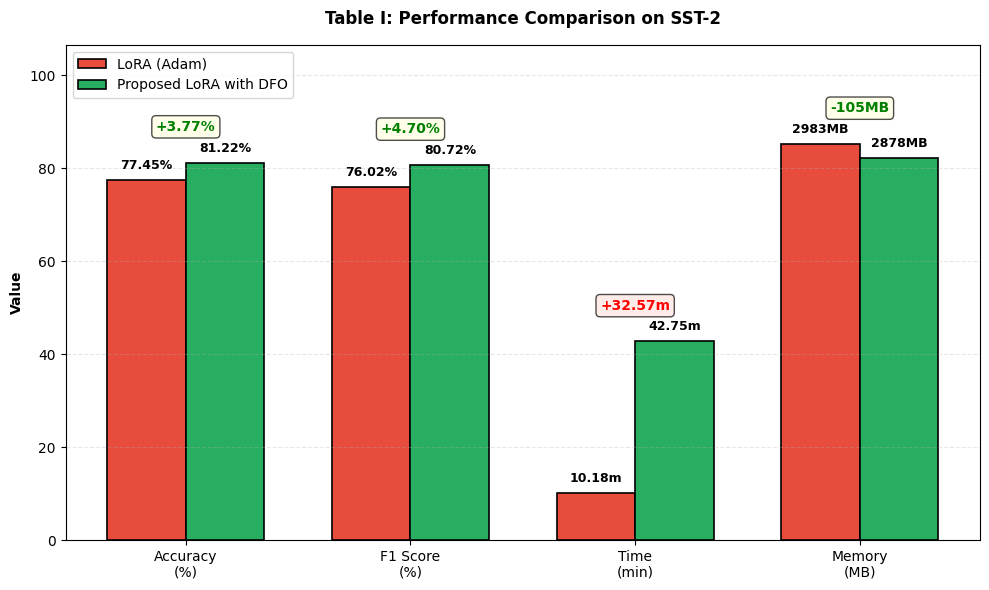

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data
metrics = ['Accuracy\n(%)', 'F1 Score\n(%)', 'Time\n(min)', 'Memory\n(MB)']
lora_adam = [77.45, 76.02, 10.18, 2983]
dfo_lora = [81.22, 80.72, 42.75, 2878]

x = np.arange(len(metrics))
width = 0.35


memory_scale = 35
lora_display = [77.45, 76.02, 10.18, 2983/memory_scale]
dfo_display = [81.22, 80.72, 42.75, 2878/memory_scale]

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, lora_display, width,
               label='LoRA (Adam)', color='#E74C3C',
               edgecolor='black', linewidth=1.2)

bars2 = ax.bar(x + width/2, dfo_display, width,
               label='Proposed LoRA with DFO', color='#27AE60',
               edgecolor='black', linewidth=1.2)

max_height = max(max(lora_display), max(dfo_display))
ax.set_ylim(0, max_height * 1.25)

# Labels
labels_lora = ['77.45%', '76.02%', '10.18m', '2983MB']
labels_dfo = ['81.22%', '80.72%', '42.75m', '2878MB']

offset = max_height * 0.02

for bar, label in zip(bars1, labels_lora):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2,
            height + offset,
            label,
            ha='center', va='bottom',
            fontsize=9, fontweight='bold')

for bar, label in zip(bars2, labels_dfo):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2,
            height + offset,
            label,
            ha='center', va='bottom',
            fontsize=9, fontweight='bold')

improvements = ['+3.77%', '+4.70%', '+32.57m', '-105MB']
colors = ['green', 'green', 'red', 'green']

for i, (imp, color) in enumerate(zip(improvements, colors)):
    ax.text(x[i],
            max(lora_display[i], dfo_display[i]) + max_height*0.08,
            imp,
            ha='center',
            fontsize=10,
            fontweight='bold',
            color=color,
            bbox=dict(boxstyle='round',
                      facecolor='lightyellow' if color=='green' else 'mistyrose',
                      alpha=0.7))

# Formatting
ax.set_ylabel('Value', fontweight='bold')
ax.set_title('Table I: Performance Comparison on SST-2',
             fontweight='bold', pad=15)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()

save_path = '/content/drive/MyDrive/FYP_GradientFree_LoRA/table_x_compact_fixed.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✅ Figure saved to: {save_path}")

plt.show()


DFO SIGNIFICANCE IN PROJECT

1. Very Large Language Models (LLMs)

Billions of parameters

Backpropagation is expensive

Activation storage is heavy

2. Few-Shot Learning

Very small dataset

Gradients can be noisy

High risk of overfitting

3. Parameter-Efficient Setting (LoRA)

Only small subset optimized

Intrinsic low-dimensional search space